In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
print("All Libraries imported successfully")

All Libraries imported successfully


In [2]:
dfs=sns.load_dataset("titanic")

In [3]:
#save the csv file
dfs.to_csv("titanic.csv", index=False)

In [4]:
df=pd.read_csv("titanic.csv")

In [ ]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
print("shape of the dataframe:",df.shape)

shape of the dataframe: (891, 15)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [ ]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
#percentage of missing values
df.isnull().sum()/len(df)*100

,0
survived,0.000000
pclass,0.000000
sex,0.000000
age,19.865320
sibsp,0.000000
parch,0.000000
fare,0.000000
embarked,0.224467
class,0.000000
who,0.000000


Handling missing values

"age" column is having missing values between 5%-30% so we need to impute by either mean,median or mode
"deck" column is having 77% of missing values so we can drop the column.
"embarked" and "embark_town" column is having < 5% of missing values so we can drop those rows.

In [ ]:
df.dropna(subset=["embarked","embark_town"],inplace=True)

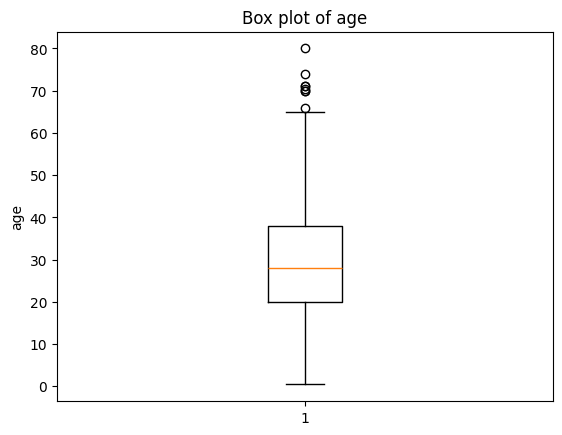

In [ ]:
#Box plot to age to understand what to impute
plt.boxplot(df["age"].dropna())
plt.title("Box plot of age")
plt.ylabel("age")
plt.show()

On observing the boxplot age do contain outliers so impute with median.

In [ ]:
df["age"]=df["age"].fillna(df["age"].median()).astype(int)

In [ ]:
df=df.drop(columns=["deck"])

In [ ]:
#checking duplicates
df.duplicated().sum()

np.int64(120)

In [ ]:
#dropping the duplicate rows
df.drop_duplicates(inplace=True)

Univariate Analysis

Histogram plot is used to visualize the distribution of a numerical variable.

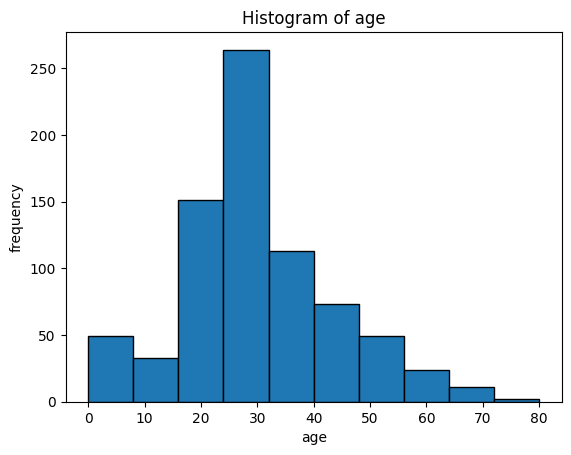

In [ ]:
#Histogram plot of age column
plt.hist(df["age"],bins=10,edgecolor="black")
plt.title("Histogram of age")
plt.xlabel("age")
plt.ylabel("frequency")
plt.show()

age values are right skewed i.e., mean>median
value "80" is an outlier.

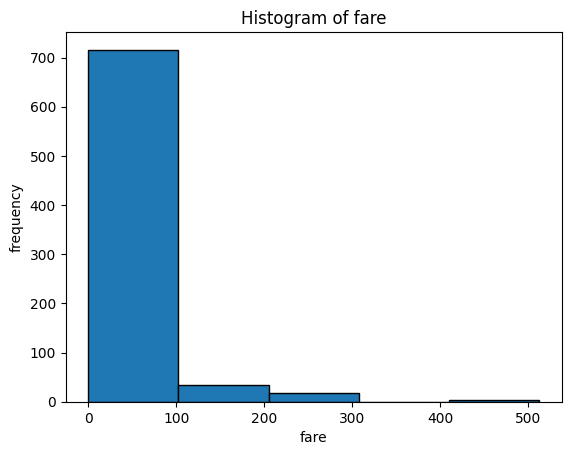

In [ ]:
#Histogram of fare
plt.hist(df["fare"],bins=5,edgecolor="black")
plt.title("Histogram of fare")
plt.xlabel("fare")
plt.ylabel("frequency")
plt.show()

fare is right skewed and 512 is an outlier. mean>median

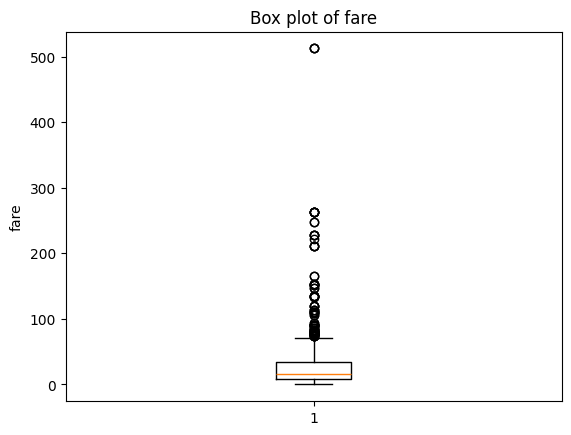

In [ ]:
#box plot of fare
plt.boxplot(df["fare"])
plt.title("Box plot of fare")
plt.ylabel("fare")
plt.show()

In [ ]:
#IQR rule of age
Q1_age=df["age"].quantile(0.25)
Q3_age=df["age"].quantile(0.75)
IQR_age=Q3_age-Q1_age

lower_age=Q1_age-1.5*IQR_age
upper_age=Q3_age+1.5*IQR_age

outliers_age=df[(df["age"]<lower_age) | (df["age"]>upper_age)]
print(outliers_age)

     survived  pclass     sex  age  sibsp  parch      fare embarked   class    who  adult_male  embark_town alive  \
33          0       2    male   66      0      0   10.5000        S  Second    man        True  Southampton    no   
54          0       1    male   65      0      1   61.9792        C   First    man        True    Cherbourg    no   
94          0       3    male   59      0      0    7.2500        S   Third    man        True  Southampton    no   
96          0       1    male   71      0      0   34.6542        C   First    man        True    Cherbourg    no   
116         0       3    male   70      0      0    7.7500        Q   Third    man        True   Queenstown    no   
170         0       1    male   61      0      0   33.5000        S   First    man        True  Southampton    no   
232         0       2    male   59      0      0   13.5000        S  Second    man        True  Southampton    no   
252         0       1    male   62      0      0   26.5500      

In [6]:
#IQR rule for fare
Q1_fare=df["fare"].quantile(0.25)
Q3_fare=df["fare"].quantile(0.75)
IQR_fare=Q3_fare-Q1_fare

lower_fare=Q1_fare-1.5*IQR_fare
upper_fare=Q3_fare+1.5*IQR_fare

outliers_fare=df[(df["fare"]<lower_fare) | (df["fare"]>upper_fare)]
print(outliers_fare)

     survived  pclass     sex   age  sibsp  parch      fare embarked  class  \
1           1       1  female  38.0      1      0   71.2833        C  First   
27          0       1    male  19.0      3      2  263.0000        S  First   
31          1       1  female   NaN      1      0  146.5208        C  First   
34          0       1    male  28.0      1      0   82.1708        C  First   
52          1       1  female  49.0      1      0   76.7292        C  First   
..        ...     ...     ...   ...    ...    ...       ...      ...    ...   
846         0       3    male   NaN      8      2   69.5500        S  Third   
849         1       1  female   NaN      1      0   89.1042        C  First   
856         1       1  female  45.0      1      1  164.8667        S  First   
863         0       3  female   NaN      8      2   69.5500        S  Third   
879         1       1  female  56.0      0      1   83.1583        C  First   

       who  adult_male deck  embark_town alive  alo

In [ ]:
#calculating mode,mean,median for fare
mode_fare=df["fare"].mode()[0]
mean_fare=df["fare"].mean()
median_fare=df["fare"].median()
print(f"mode of fare is {mode_fare}")
print(f"mean of fare is {mean_fare}")
print(f"median of fare is {median_fare}")

mode of fare is 13.0
mean of fare is 34.89523159947985
median of fare is 16.0


mean>median>mode which means right skewness for fare

In [ ]:
#calculating mode,mean,median for age
mode_age=df["age"].mode()[0]
mean_age=df["age"].mean()
median_age=df["age"].median()
print(f"mode of age is {mode_age}")
print(f"mean of age is {mean_age}")
print(f"median of age is {median_age}")

mode of age is 28
mean of age is 29.516254876462938
median of age is 28.0


mean>median,mode right skewness for age

Bivariate Analysis

In [ ]:
#survival rate broken down by sex column
male_rate=df[df["sex"]=="male"]["survived"].mean()*100
female_rate=df[df["sex"]=="female"]["survived"].mean()*100
print(f"survival rate of males is {male_rate}")
print(f"survival rate of females is {female_rate}")

survival rate of males is 21.666666666666668
survival rate of females is 73.70242214532871


In [ ]:
#survival rate broken down by pclass
first_class=df[df["pclass"]==1]["survived"].mean()*100
second_class=df[df["pclass"]==2]["survived"].mean()*100
third_class=df[df["pclass"]==3]["survived"].mean()*100
print(f"survival rate of class 1 is {first_class}")
print(f"survival rate of class 2 is {second_class}")
print(f"survival rate of class 3 is {third_class}")

survival rate of class 1 is 62.980769230769226
survival rate of class 2 is 50.306748466257666
survival rate of class 3 is 26.13065326633166


In [ ]:
#survival rate broken down by both sex and pclass
female_first=df[(df["sex"]=="female") & (df["pclass"]==1)]["survived"].mean()*100
female_second=df[(df["sex"]=="female") & (df["pclass"]==2)]["survived"].mean()*100
female_third=df[(df["sex"]=="female") & (df["pclass"]==3)]["survived"].mean()*100

male_first=df[(df["sex"]=="male") & (df["pclass"]==1)]["survived"].mean()*100
male_second=df[(df["sex"]=="male") & (df["pclass"]==2)]["survived"].mean()*100
male_third=df[(df["sex"]=="male") & (df["pclass"]==3)]["survived"].mean()*100

print(f"survival rate of female in first class is {female_first}")
print(f"survival rate of female in second class is {female_second}")
print(f"survival rate of female in third class is {female_third}")
print(f"survival rate of male in first class is {male_first}")
print(f"survival rate of male in second class is {male_second}")
print(f"survival rate of male in third class is {male_third}")

survival rate of female in first class is 96.7032967032967
survival rate of female in second class is 91.54929577464789
survival rate of female in third class is 47.24409448818898
survival rate of male in first class is 36.75213675213676
survival rate of male in second class is 18.478260869565215
survival rate of male in third class is 16.236162361623617


In [ ]:
# calculate correlation matrix
correlation_matrix=df[["age","pclass","sibsp","parch","fare","survived"]].corr()
print(correlation_matrix)

               age    pclass     sibsp     parch      fare  survived
age       1.000000 -0.339529 -0.278525 -0.182048  0.089689 -0.084003
pclass   -0.339529  1.000000  0.087134  0.038838 -0.553056 -0.326331
sibsp    -0.278525  0.087134  1.000000  0.378238  0.133998 -0.037298
parch    -0.182048  0.038838  0.378238  1.000000  0.191153  0.070916
fare      0.089689 -0.553056  0.133998  0.191153  1.000000  0.244868
survived -0.084003 -0.326331 -0.037298  0.070916  0.244868  1.000000


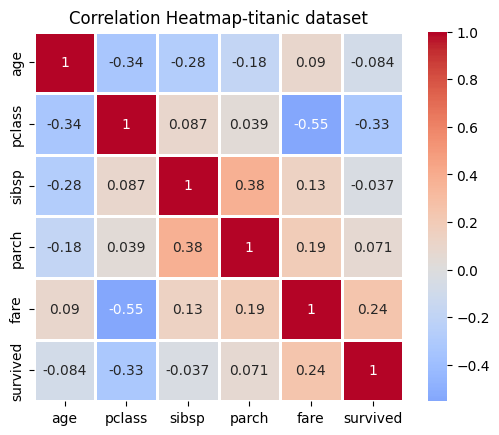

In [ ]:
#heat map
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm',
            center=0, square=True, linewidths=1)
plt.title("Correlation Heatmap-titanic dataset")
plt.show()

top two highest abs(correlation) pairs - (sibsp-parch)-0.38 weak correlation,
(pclass,fare)- 0.55 moderate correlation.

Multivariate analysis

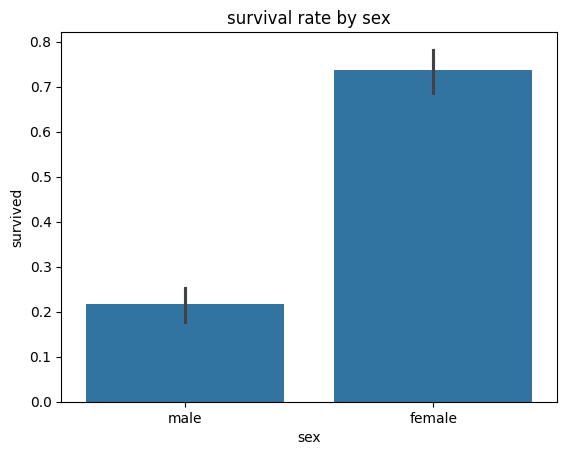

In [ ]:
#Bar plot for survived and sex.
sns.barplot(data=df,x="sex",y="survived")
plt.title("survival rate by sex")
plt.show()

females has higher survival rate than male

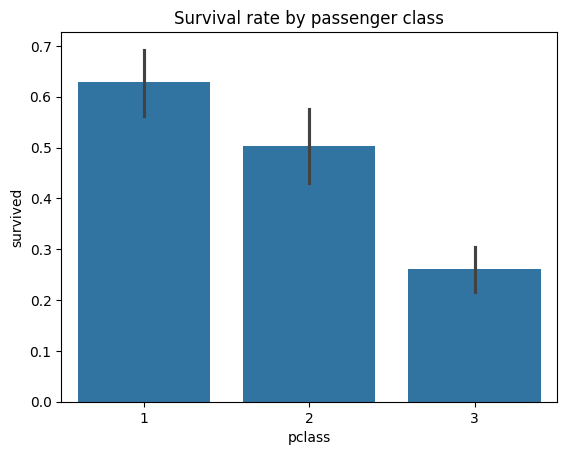

In [ ]:
#Bar plot for survived and pclass
sns.barplot(data=df,x="pclass",y="survived")
plt.title("Survival rate by passenger class")
plt.show()

first class passengers have higher survival rate followed by second and third classes.

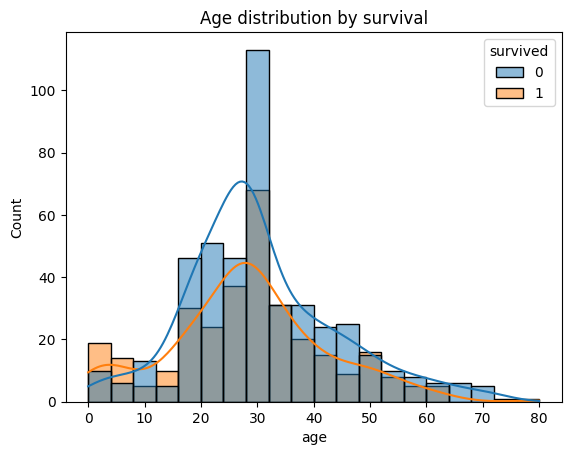

In [ ]:
#Histogram of age distribution by survival
sns.histplot(data=df,x="age",hue="survived",bins=20,kde=True)
plt.title("Age distribution by survival")
plt.show()

Younger age people have higher survival rates.

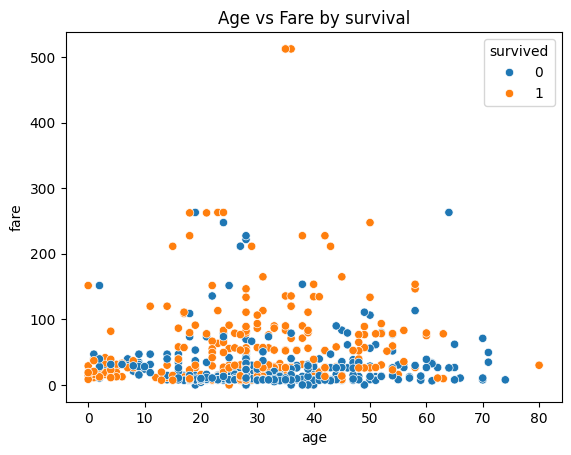

In [ ]:
#scatter plot of survived of age vs fare
sns.scatterplot(data=df,x="age",y="fare",hue="survived")
plt.title("Age vs Fare by survival")
plt.show()

Passengers paying higher fares generally had better survival chances and young age people(especially children) have higher survival rate.

Exploratory check

In [ ]:
df_copy=df.copy()

In [ ]:
#numerical columns before scaling
numeric_cols=["age","fare"]
print("Before Scaling:\n")
print(df_copy[numeric_cols].describe().round(1))

Before Scaling:

         age   fare
count  769.0  769.0
mean    29.5   34.9
std     13.8   52.5
min      0.0    0.0
25%     21.0    8.0
50%     28.0   16.0
75%     36.0   34.0
max     80.0  512.3


In [ ]:
#using standard scaler and after scaling results
scaler=StandardScaler()
df_copy[numeric_cols]=scaler.fit_transform(df_copy[numeric_cols])
print("After Scaling:\n")
print(df_copy[numeric_cols].describe().round(2))

After Scaling:

          age    fare
count  769.00  769.00
mean     0.00   -0.00
std      1.00    1.00
min     -2.14   -0.66
25%     -0.62   -0.51
50%     -0.11   -0.36
75%      0.47   -0.02
max      3.67    9.09


After scaling the mean and standard deviation of age and fare is 0 and 1 respectively.

In [ ]:
#saving the cleaned dataset for other purposes
df.to_csv("titanic_cleaned.csv",index=False)